In [131]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/reza2866/datamining/movie_metadata.csv


In [132]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "./movie_metadata.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "reza2866/datamining",
  file_path,
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df.head())

/tmp/ipykernel_58/2177651006.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


First 5 records:    color      director_name  num_critic_for_reviews  duration  \
0  Color      James Cameron                   723.0     178.0   
1  Color     Gore Verbinski                   302.0     169.0   
2  Color         Sam Mendes                   602.0     148.0   
3  Color  Christopher Nolan                   813.0     164.0   
4    NaN        Doug Walker                     NaN       NaN   

   director_facebook_likes  actor_3_facebook_likes      actor_2_name  \
0                      0.0                   855.0  Joel David Moore   
1                    563.0                  1000.0     Orlando Bloom   
2                      0.0                   161.0      Rory Kinnear   
3                  22000.0                 23000.0    Christian Bale   
4                    131.0                     NaN        Rob Walker   

   actor_1_facebook_likes        gross                           genres  ...  \
0                  1000.0  760505847.0  Action|Adventure|Fantasy|Sci-Fi  ...   

In [133]:
! pip install sweetviz

In [134]:
import pandas as pd
import sweetviz as sv

In [135]:
df = pd.read_csv("/kaggle/input/datasets/reza2866/datamining/movie_metadata.csv")

df.head(10)

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
0,Color,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,...,3054.0,English,USA,PG-13,237000000.0,2009.0,936.0,7.9,1.78,33000
1,Color,Gore Verbinski,302.0,169.0,563.0,1000.0,Orlando Bloom,40000.0,309404152.0,Action|Adventure|Fantasy,...,1238.0,English,USA,PG-13,300000000.0,2007.0,5000.0,7.1,2.35,0
2,Color,Sam Mendes,602.0,148.0,0.0,161.0,Rory Kinnear,11000.0,200074175.0,Action|Adventure|Thriller,...,994.0,English,UK,PG-13,245000000.0,2015.0,393.0,6.8,2.35,85000
3,Color,Christopher Nolan,813.0,164.0,22000.0,23000.0,Christian Bale,27000.0,448130642.0,Action|Thriller,...,2701.0,English,USA,PG-13,250000000.0,2012.0,23000.0,8.5,2.35,164000
4,NaN,Doug Walker,NaN,NaN,131.0,NaN,Rob Walker,131.0,NaN,Documentary,...,NaN,NaN,NaN,NaN,NaN,NaN,12.0,7.1,NaN,0
5,Color,Andrew Stanton,462.0,132.0,475.0,530.0,Samantha Morton,640.0,73058679.0,Action|Adventure|Sci-Fi,...,738.0,English,USA,PG-13,263700000.0,2012.0,632.0,6.6,2.35,24000
6,Color,Sam Raimi,392.0,156.0,0.0,4000.0,James Franco,24000.0,336530303.0,Action|Adventure|Romance,...,1902.0,English,USA,PG-13,258000000.0,2007.0,11000.0,6.2,2.35,0
7,Color,Nathan Greno,324.0,100.0,15.0,284.0,Donna Murphy,799.0,200807262.0,Adventure|Animation|Comedy|Family|Fantasy|Musi...,...,387.0,English,USA,PG,260000000.0,2010.0,553.0,7.8,1.85,29000
8,Color,Joss Whedon,635.0,141.0,0.0,19000.0,Robert Downey Jr.,26000.0,458991599.0,Action|Adventure|Sci-Fi,...,1117.0,English,USA,PG-13,250000000.0,2015.0,21000.0,7.5,2.35,118000
9,Color,David Yates,375.0,153.0,282.0,10000.0,Daniel Radcliffe,25000.0,301956980.0,Adventure|Family|Fantasy|Mystery,...,973.0,English,UK,PG,250000000.0,2009.0,11000.0,7.5,2.35,10000


In [136]:
# exploration of data
# see data profiling with sweetViz
# report = sv.analyze(df)
# report.show_html("movie_report_01.html")

# data profiling notes
# - most of the columns have a missig values

# color: estetika (hitam putih vs berwarna).
# director_name: gaya sutradara memengaruhi kesamaan film.
# duration (in minute): durasi film bisa jadi preferensi.
# genres (butuh di pisahkan, lalu encoding ohe): fitur utama untuk kesamaan konten.
# actor_1_name, actor_2_name, actor_3_name:pemeran utama memengaruhi kesamaan film.
# plot_keywords (butuh di pisahkan, lalu encoding ohe): kata kunci cerita, sangat penting untuk similarity.
# movie_title: identitas film (digunakan sebagai referensi).
# language: bahasa film, bisa jadi preferensi.
# country: asal produksi film.
# content_rating: rating usia (PG, R, dll).
# title_year: tahun rilis, preferensi klasik vs modern.
# aspect_ratio: fitur teknis, bisa dipakai jika relevan.

# drop unrelevan columns
drop_cols = [
    'num_critic_for_reviews', 'director_facebook_likes',
    'actor_3_facebook_likes', 'actor_1_facebook_likes',
    'actor_2_facebook_likes', 'gross', 'num_voted_users',
    'cast_total_facebook_likes', 'facenumber_in_poster',
    'movie_imdb_link', 'num_user_for_reviews', 'budget',
    'imdb_score', 'movie_facebook_likes', 'aspect_ratio'
]

df = df.drop(columns=drop_cols)

In [137]:
df.isna().sum()

color              19
director_name     104
duration           15
actor_2_name       13
genres              0
actor_1_name        7
movie_title         0
actor_3_name       23
plot_keywords     153
language           14
country             5
content_rating    303
title_year        108
dtype: int64

In [138]:
df.duplicated().sum()

np.int64(122)

In [139]:
df = df.drop_duplicates()

In [140]:
# use mode for missing value in color
# use 'Unknown' for missing value in director_name
# use median for missing value in duration
# use 'Unknown' for missing value in actor 1 and actor 2 and actor 3
# use mode for country or based on language
# for plot keyword use most genre in the same director
# for language use from country or using mode
# using genre to determine missing value for content rating
# using mean median for title year

# for imputation using mean or median check data distribution

In [141]:
# handle missing values in color column
mode_color = df['color'].mode()[0]
print(mode_color)

df['color'] = df['color'].fillna(mode_color)

Color


In [142]:
# handle missing values in director_name column
df['director_name'] = df['director_name'].fillna('unknown')

In [143]:
import matplotlib.pyplot as plt

In [144]:
df['duration'].describe()

count    4906.000000
mean      107.095597
std        25.278083
min         7.000000
25%        93.000000
50%       103.000000
75%       118.000000
max       511.000000
Name: duration, dtype: float64

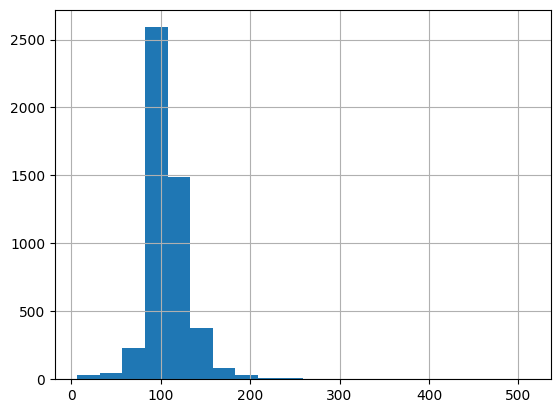

In [145]:
df['duration'].hist(bins=20)
plt.show()

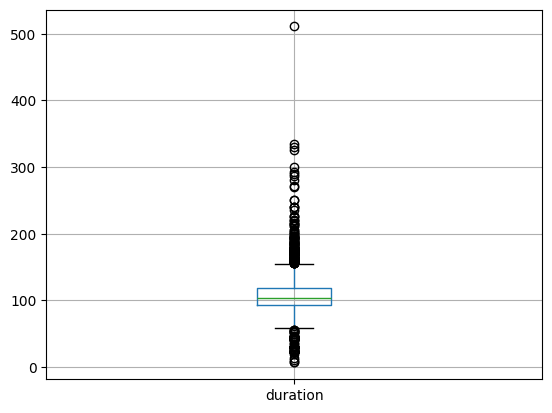

In [146]:
df.boxplot(column='duration')
plt.show()

In [147]:
# handle duration with median
median_duration = df['duration'].median()
df['duration'] = df['duration'].fillna(median_duration)

In [148]:
df['actor_1_name'] = df['actor_1_name'].fillna("unkown")
df['actor_2_name'] = df['actor_2_name'].fillna("unkown")
df['actor_3_name'] = df['actor_3_name'].fillna("unkown")

In [149]:
def impute_keywords(row):
    if pd.isna(row['plot_keywords']):
        similar = df[(df['director_name'] == row['director_name']) & (df['genres'] == row['genres']) & (df['plot_keywords'].notna())]
        if not similar.empty:
            return similar['plot_keywords'].iloc[0]
        else:
            return 'unknown'
    else:
        return row['plot_keywords']

df['plot_keywords'] = df.apply(impute_keywords, axis=1)

In [150]:
df[df['country'].isna()]

,color,director_name,duration,actor_2_name,genres,actor_1_name,movie_title,actor_3_name,plot_keywords,language,country,content_rating,title_year
4,Color,Doug Walker,103.0,Rob Walker,Documentary,Doug Walker,Star Wars: Episode VII - The Force Awakens ...,unkown,unknown,NaN,NaN,NaN,NaN
279,Color,Christopher Barnard,22.0,unkown,Comedy,Mathew Buck,"10,000 B.C.",unkown,unknown,NaN,NaN,NaN,NaN
2370,Color,unknown,43.0,Jenni 'Jwoww' Farley,Comedy|Drama|Reality-TV|Romance,Nicole 'Snooki' Polizzi,"Gone, Baby, Gone",Paul 'Pauly D' DelVecchio,lifestyle,English,NaN,TV-14,NaN
3397,Color,unknown,60.0,Joseph Gilgun,Adventure|Drama|Fantasy|Mystery,Dominic Cooper,Preacher,Ruth Negga,heaven and hell|preacher|supernatural|vampire|...,English,NaN,TV-MA,NaN
4021,Color,Daniel Petrie Jr.,88.0,Jeff Fahey,Drama|Thriller,Chris Brochu,Dawn Patrol,Rita Wilson,desert|held at gunpoint|marine|revenge|sex on ...,English,NaN,NaN,2014.0


In [151]:
def impute_country(row):
    if pd.isna(row['country']):
        if not pd.isna(row['language']):
            mode_country_lan_based = df['country'][df['language'] == row['language']].mode()[0]
            return mode_country_lan_based
        else:
            return 'unknown'
    else:
        return row['country']
            
df['country'] = df.apply(impute_country, axis=1)

In [152]:
df[['country', 'language']][df['country'] == 'Unknown']

,country,language


In [153]:
def impute_lan(row):
    if pd.isna(row['language']):
        if row['country'] != 'Unknown':
            # ambil semua bahasa dari negara yang sama
            langs = df.loc[df['country'] == row['country'], 'language'].dropna()
            if not langs.empty:
                return langs.mode()[0]   # isi dengan mode
            else:
                return 'unknown'         # fallback jika tidak ada data
        else:
            return 'unknown'
    else:
        return row['language']

df['language'] = df.apply(impute_lan, axis=1)


In [154]:
df.isna().sum()

color               0
director_name       0
duration            0
actor_2_name        0
genres              0
actor_1_name        0
movie_title         0
actor_3_name        0
plot_keywords       0
language            0
country             0
content_rating    301
title_year        106
dtype: int64

In [155]:
df['content_rating'].value_counts()

content_rating
R            2070
PG-13        1412
PG            686
Not Rated     115
G             112
Unrated        59
Approved       54
TV-14          30
TV-MA          18
TV-PG          13
X              12
TV-G           10
Passed          9
NC-17           7
GP              6
M               5
TV-Y            1
TV-Y7           1
Name: count, dtype: int64

In [156]:
# content_rating need normalization, 
# dataset mixes modern MPAA ratings (G, PG, PG‑13, R, NC‑17), 
# TV ratings (TV‑PG, TV‑14, TV‑MA), 
# and legacy ratings (Approved, Passed, M, GP).
# Keep "Unrated" and 
# "Not Rated" distinct from "Unknown" (missing data).


# R -> R            = Modern restricted rating
# PG‑13 -> PG‑13    = Modern parental caution
# PG -> PG          = Modern parental guidance
# G -> G            = General audiences
# NC‑17 -> NC‑17    = Adults only
# X -> NC‑17        = Obsolete adult-only, map to NC‑17
# M / GP -> PG      = Transitional ratings, equivalent to PG
# TV‑G -> G         = TV general audience
# TV‑PG -> PG       = TV parental guidance
# TV‑14 -> PG‑13    = TV parental caution (14+)
# TV‑MA -> R        = TV mature audiences
# TV‑Y / TV‑Y7 -> G = Children’s programming
# Unrated / Not Rated -> Unrated       = Distinct from missing values
# Approved / Passed -> Legacy_Approved = Hays Code seal (1930–1968)

def impute_con_rat(row):
    if not pd.isna(row['content_rating']):
        if row['content_rating'] == 'Not Rated':
            return 'Unrated'
        elif (row['content_rating'] == 'Passed') or (row['content_rating'] == 'Approved'):
            return 'Legacy_Approved'
        elif (row['content_rating'] == 'TV-Y') or (row['content_rating'] == 'TV‑Y7') or (row['content_rating'] == 'TV‑G'):
            return 'G'
        elif (row['content_rating'] == 'R') or (row['content_rating'] == 'TV‑MA'):
            return 'R'
        elif (row['content_rating'] == 'GP') or (row['content_rating'] == 'M') or (row['content_rating'] == 'TV‑PG'):
            return 'PG'
        elif (row['content_rating'] == 'TV-14'):
            return 'PG-13'
        elif (row['content_rating'] == 'X'):
            return 'NC-17'
        else:
            return row['content_rating']
    else:
        return 'unknown'

df['content_rating'] = df.apply(impute_con_rat, axis=1)

In [157]:
df.isna().sum(0)

color               0
director_name       0
duration            0
actor_2_name        0
genres              0
actor_1_name        0
movie_title         0
actor_3_name        0
plot_keywords       0
language            0
country             0
content_rating      0
title_year        106
dtype: int64

In [158]:
df_analysis = df.copy()
df_analysis['title_year'] = df_analysis['title_year'].fillna('unknown')

df_analysis.to_csv('./df_movie_analysis.csv', index=False)

<Axes: >

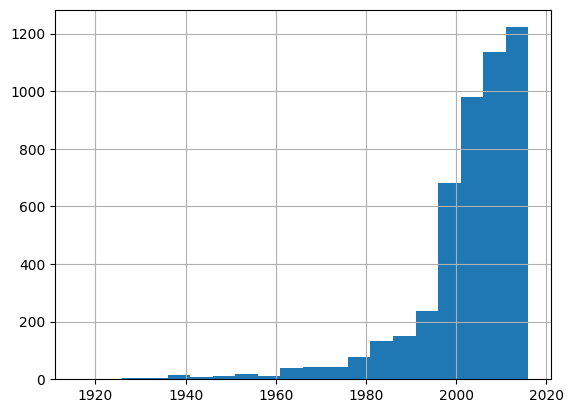

In [159]:
df['title_year'].hist(bins=20)

In [160]:
# Buat kolom flag Unknown
df['year_unknown'] = df['title_year'].isna().astype(int)

# Isi nilai NaN dengan median
median_year = df['title_year'].median()
df['title_year'] = df['title_year'].fillna(median_year)

In [161]:
df.isna().sum()

color             0
director_name     0
duration          0
actor_2_name      0
genres            0
actor_1_name      0
movie_title       0
actor_3_name      0
plot_keywords     0
language          0
country           0
content_rating    0
title_year        0
year_unknown      0
dtype: int64

In [162]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# untuk duration
df['duration'] = scaler.fit_transform(df[['duration']])

# untuk title_year
df['title_year'] = scaler.fit_transform(df[['title_year']])


In [163]:
cols = ['color', 'director_name', 'actor_2_name', 'actor_1_name', 'genres', 'movie_title', 'actor_3_name', 'plot_keywords', 'language',	'country', 'content_rating']

df[cols] = df[cols].apply(lambda x: x.str.lower())
df[cols] = df[cols].apply(lambda x: x.str.strip())

In [164]:
df['plot_keywords'] = df['plot_keywords'].apply(
    lambda x: x.split('|') if isinstance(x, str) and x.lower() != 'unknown' else []
)

df['genres'] = df['genres'].apply(
    lambda x: x.split('|') if isinstance(x, str) and x.lower() != 'unknown' else []
)


TF‑IDF → untuk teks (plot_keywords, genres).

Word2Vec → untuk entitas (director_name, actor_1_name, actor_2_name, actor_3_name).

Numerik → (duration, title_year).

Kategorikal → (content_rating, year_unknown) → One‑Hot Encoding.

Gabungkan semua vektor → hasilkan representasi film yang kaya.

Cosine similarity → rekomendasi film mirip.

Language → grouping bahasa populer + "Other".

Country → gunakan frequency encoding atau grouping (USA, India, UK, Other).

In [165]:
def grouping_lan(row):
    top_languages = df['language'].value_counts().head(10).index.tolist()
    if row['language'] not in top_languages:
        return 'other'
    else:
        return row['language']

df['language'] = df.apply(grouping_lan, axis=1)

In [166]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

# --- Frequency Encoding untuk country ---
for col in ['country']:
    freq_map = df[col].value_counts().to_dict()
    df[col + '_freq'] = df[col].map(freq_map)

# --- One-Hot Encoding untuk content_rating dan language ---
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

# content_rating
content_rating_encoded = ohe.fit_transform(df[['content_rating']])
content_rating_df = pd.DataFrame(
    content_rating_encoded,
    columns=ohe.get_feature_names_out(['content_rating'])
)

# language
language_encoded = ohe.fit_transform(df[['language']])
lan_df = pd.DataFrame(
    language_encoded,
    columns=ohe.get_feature_names_out(['language'])
)

# gabungkan hasil OHE ke DataFrame
df = pd.concat(
    [df.reset_index(drop=True), content_rating_df.reset_index(drop=True), lan_df.reset_index(drop=True)],
    axis=1
)


In [167]:
df.columns

Index(['color', 'director_name', 'duration', 'actor_2_name', 'genres',
       'actor_1_name', 'movie_title', 'actor_3_name', 'plot_keywords',
       'language', 'country', 'content_rating', 'title_year', 'year_unknown',
       'country_freq', 'content_rating_g', 'content_rating_legacy_approved',
       'content_rating_nc-17', 'content_rating_pg', 'content_rating_pg-13',
       'content_rating_r', 'content_rating_tv-g', 'content_rating_tv-ma',
       'content_rating_tv-pg', 'content_rating_tv-y7',
       'content_rating_unknown', 'content_rating_unrated',
       'language_cantonese', 'language_english', 'language_french',
       'language_german', 'language_hindi', 'language_italian',
       'language_japanese', 'language_mandarin', 'language_other',
       'language_russian', 'language_spanish'],
      dtype='object')

In [168]:
from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.models import Word2Vec
import numpy as np
from sklearn.preprocessing import normalize

# TF‑IDF untuk teks
df['plot_keywords_str'] = df['plot_keywords'].apply(lambda x: ' '.join(x) if isinstance(x, list) else '')
df['genres_str'] = df['genres'].apply(lambda x: ' '.join(x) if isinstance(x, list) else '')

text_docs = df['plot_keywords_str'] + " " + df['genres_str']
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(text_docs)

# using word2vec for 'director_name','actor_1_name','actor_2_name','actor_3_name'
films_entities = df[['director_name','actor_1_name','actor_2_name','actor_3_name']].values.tolist()
model = Word2Vec(films_entities, vector_size=50, window=3, min_count=1, sg=1)

def film_vector(entities):
    vectors = [model.wv[e] for e in entities if e in model.wv]
    return np.mean(vectors, axis=0)

entity_embeddings = np.array([film_vector(f) for f in films_entities])

# ambil fitur numerik/kategorikal
numeric_features = df[['duration','title_year','country_freq']].values
categorical_features = df[['content_rating_g', 'content_rating_legacy_approved',
       'content_rating_nc-17', 'content_rating_pg', 'content_rating_pg-13',
       'content_rating_r', 'content_rating_tv-g', 'content_rating_tv-ma',
       'content_rating_tv-pg', 'content_rating_tv-y7',
       'content_rating_unknown', 'content_rating_unrated','language_cantonese', 'language_english', 'language_french',
       'language_german', 'language_hindi', 'language_italian',
       'language_japanese', 'language_mandarin', 'language_other',
       'language_russian', 'language_spanish']].values  # hasil OHE

# gabungkan semua
combined_embeddings = np.hstack([
    normalize(tfidf_matrix).toarray(),
    entity_embeddings,
    numeric_features,
    categorical_features
])

In [169]:
from sklearn.metrics.pairwise import cosine_similarity

# hitung similarity antar film
similarity_matrix = cosine_similarity(combined_embeddings)

# fungsi rekomendasi
def recommend(title, top_n=5):
    # cari index film
    matches = df[df['movie_title'].str.strip().str.lower() == title.strip().lower()]
    if matches.empty:
        return f"Film '{title}' tidak ditemukan dalam dataset."
    idx = matches.index[0]
    # ambil skor similarity
    sim_scores = list(enumerate(similarity_matrix[idx]))
    # urutkan dari paling mirip
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    # ambil top_n (skip diri sendiri di index 0)
    sim_scores = sim_scores[1:top_n+1]
    movie_indices = [i[0] for i in sim_scores]
    return df['movie_title'].iloc[movie_indices]


In [171]:
recommend('Gone, Baby, Gone')

4919    shanghai calling
4338           the salon
176           miami vice
4830    romantic schemer
1606           baby mama
Name: movie_title, dtype: object